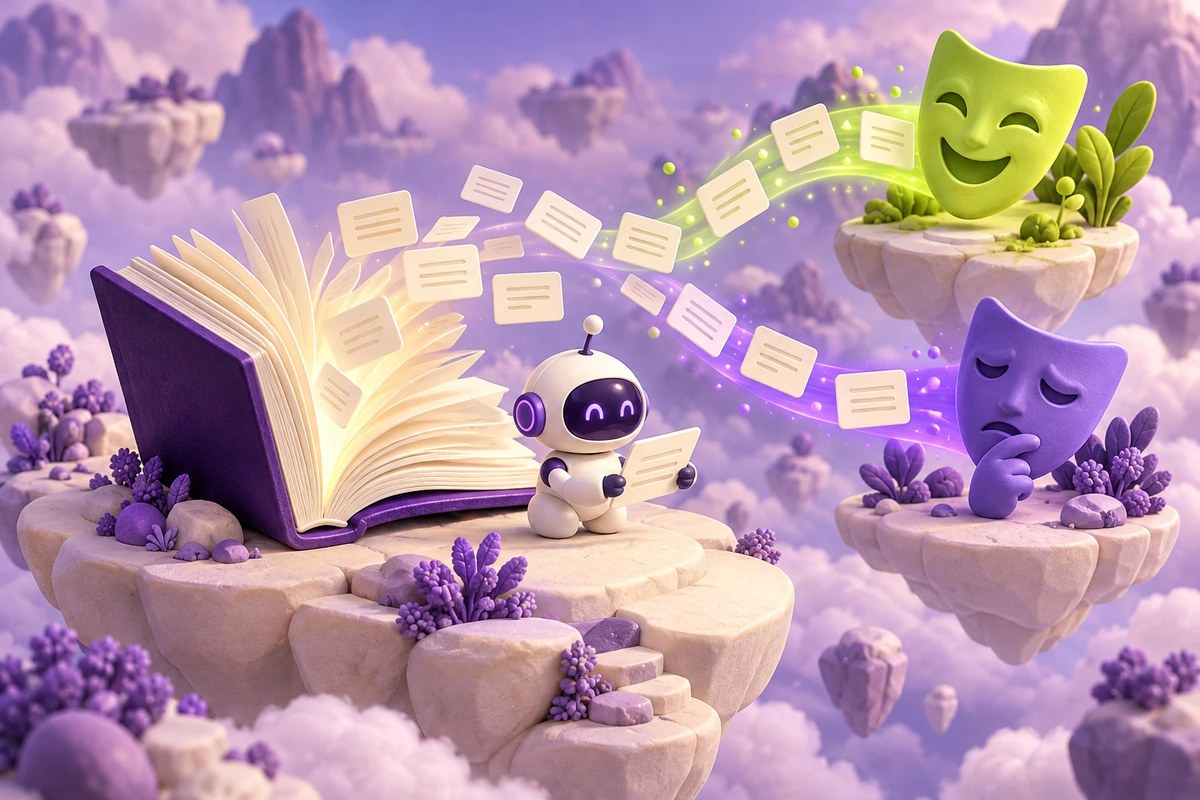

AI PATH · Нейросети для текста · Урок 026

# Тональность IMDb: локальные признаки Conv1D

Как свёрточная сеть превращает последовательность слов в оценку отзыва.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-026-goal"></a>
## Что вы разберёте

Разобрать Embedding, свёртки и pooling на задаче бинарной тональности.

### Перед началом

- Классификация и функция потерь
- Последовательности токенов и Keras

### Что понадобится

- TensorFlow/Keras, NumPy и Matplotlib
- Доступ к загрузке IMDb через keras.datasets.imdb
- Среда IPython/Colab для исходной команды выбора TensorFlow

## Навигация по уроку

- [Цель и подготовка](#ai-026-goal)
- [Карта урока](#ai-026-map)
- [Среда и импорты](#ai-026-section-01)
- [Словарь IMDb](#ai-026-section-02)
- [Длина отзыва](#ai-026-section-03)
- [Свёрточный классификатор](#ai-026-section-04)
- [Обучение](#ai-026-section-05)
- [Отложенная оценка](#ai-026-section-06)
- [Проверьте понимание](#ai-026-practice)
- [Источники и ограничения](#ai-026-provenance)

<a id="ai-026-map"></a>
## Карта урока

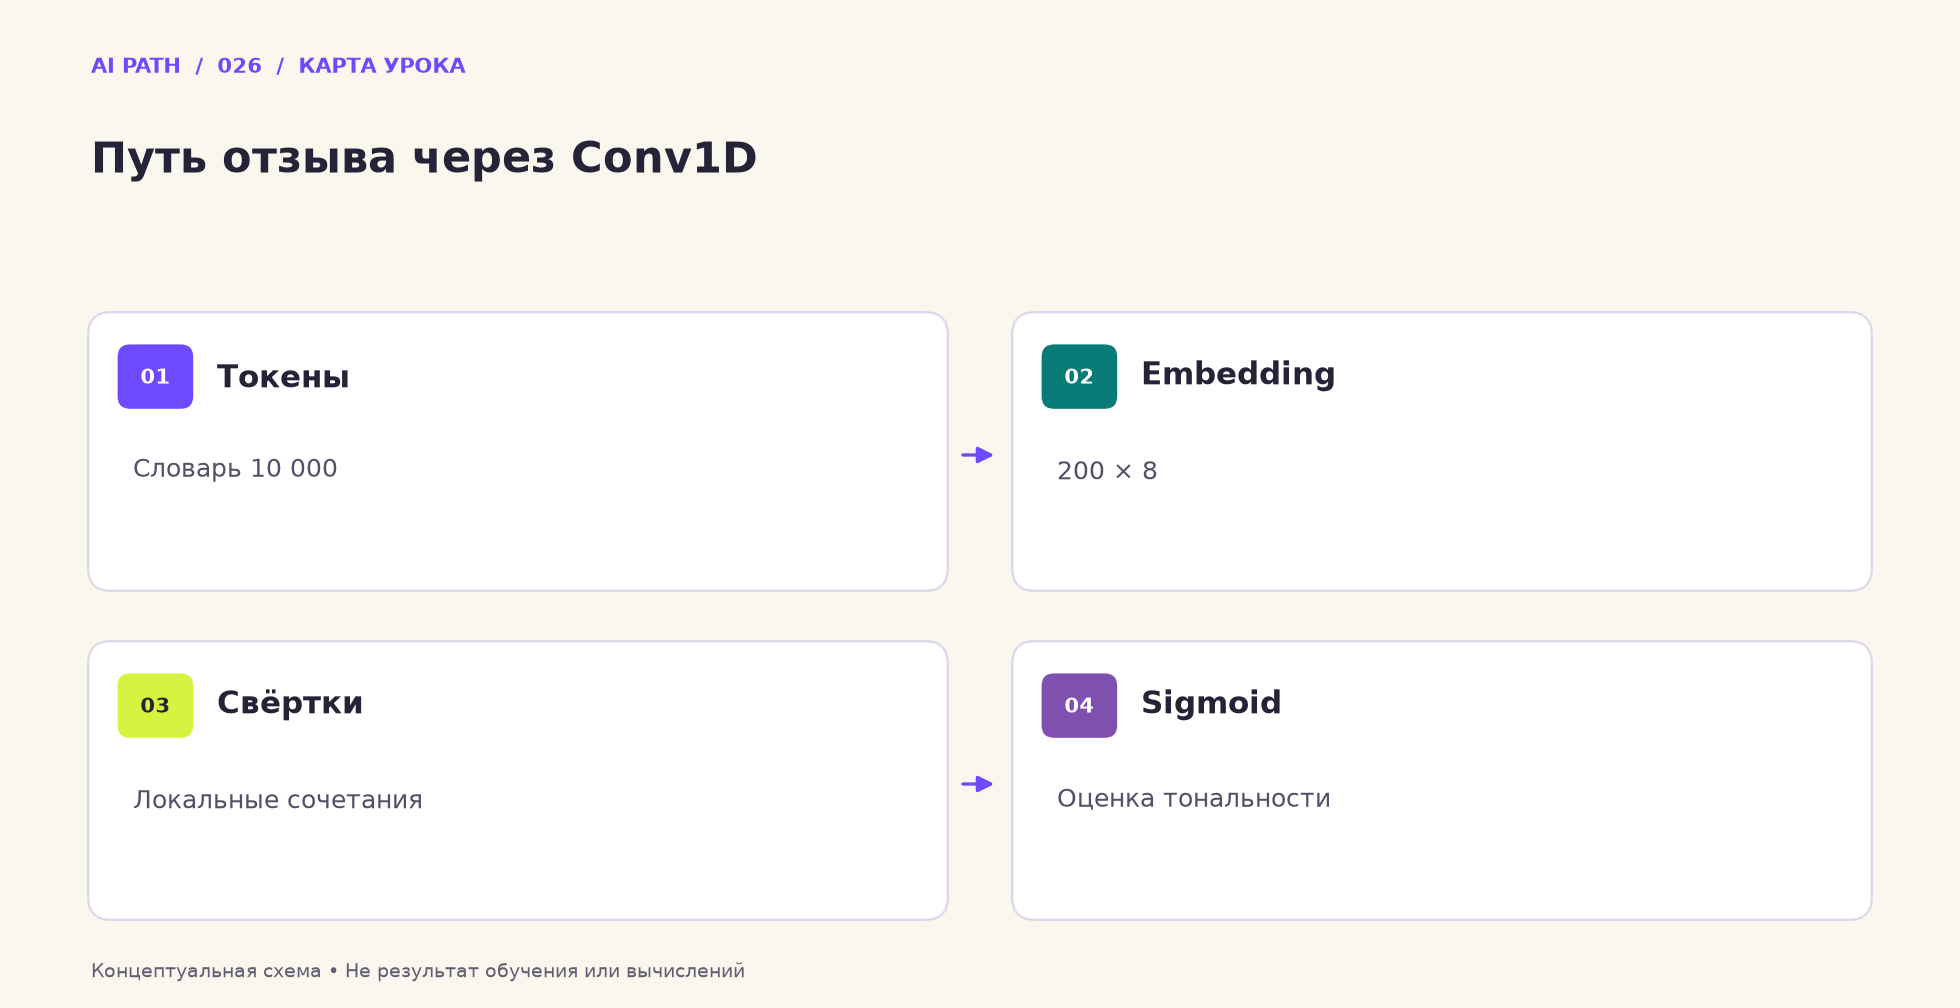

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Токены** — Словарь 10 000
2. **Embedding** — 200 × 8
3. **Свёртки** — Локальные сочетания
4. **Sigmoid** — Оценка тональности

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/NLP_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%A0%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_Conv1d_(accuracy_0_8533).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Определение тональности текста отзывов на фильмы IMDB с помощью одномерной сверточной нейросети



Чтобы запускать и редактировать код, сохраните копию этого ноутбука себе (File->Save a copy in Drive...). Свою копию вы сможете изменять и запускать.

Не забудьте подключить GPU, чтобы сеть обучалась быстрее (Runtime -> Change Runtime Type -> Hardware Accelerator -> GPU).

<a id="ai-026-section-01"></a>
## 01 · Среда и импорты

Проверьте совместимость исходной Colab-команды до работы с моделью.

_Далее — исходные ячейки учебного материала._

In [ ]:
%tensorflow_version 2.x
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 

<a id="ai-026-section-02"></a>
## 02 · Словарь IMDb

Вход ограничен 10 000 индексами; метка относится к целому отзыву.

_Далее — исходные ячейки учебного материала._

## Загружаем данные

In [ ]:
max_words=10000

In [ ]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_words)

17465344/17464789 [==============================] - 0s 0us/step


<a id="ai-026-section-03"></a>
## 03 · Длина отзыва

Padding и обрезка приводят последовательности к 200 позициям.

_Далее — исходные ячейки учебного материала._

## Подготовка данных для обучения

In [ ]:
maxlen = 200

In [ ]:
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

In [ ]:
x_train[5002]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    1,  103,   51,   13,  197,   16,    6, 4796,
        239,    7,  107,  555,   11,  132,   39, 8921, 1872,  138,   16,
       4093, 1768, 2959,   34, 1620,    2,   11,    4,  755,   12,   43,
        286,    4,  172,  209,    2,    5, 5938,   17, 1000,   34, 1768,
        279,   29, 3892,   89,  338,    4,  114,   16, 1240, 1747,  103,
       3844, 3819,    8,  169, 2875,  112, 7062,   34,  160,  132,   29,
        100,   24,  535,  101,  250,    8,  858,   15,  196,   19,   57,
       3154,   39,   90,    5,   24,  169, 3533,   

<a id="ai-026-section-04"></a>
## 04 · Свёрточный классификатор

Проследите формы после Embedding, двух Conv1D и двух pooling-слоёв.

_Далее — исходные ячейки учебного материала._

## Создание нейронной сети

In [ ]:
model = Sequential()
model.add(Embedding(max_words, 8, input_length=maxlen))
model.add(Conv1D(100, 5, activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(Conv1D(200, 5, activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (None, 200, 8)            80000     
_________________________________________________________________
conv1d (Conv1D)              (None, 196, 100)          4100      
_________________________________________________________________
max_pooling1d (MaxPooling1D) (None, 98, 100)           0         
_________________________________________________________________
conv1d_1 (Conv1D)            (None, 94, 200)           100200    
_________________________________________________________________
max_pooling1d_1 (MaxPooling1 (None, 47, 200)           0         
_________________________________________________________________
flatten (Flatten)            (None, 9400)              0         
_________________________________________________________________
dense (Dense)                (None, 128)               1

<a id="ai-026-section-05"></a>
## 05 · Обучение

Пять эпох и validation_split дают кривые для наблюдения за переобучением.

_Далее — исходные ячейки учебного материала._

## Обучаем нейронную сеть

In [ ]:
history = model.fit(x_train, 
                    y_train, 
                    epochs=5,
                    batch_size=128,
                    validation_split=0.1)

Epoch 1/5
176/176 [==============================] - 3s 14ms/step - loss: 0.5184 - accuracy: 0.6955 - val_loss: 0.3228 - val_accuracy: 0.8652
Epoch 2/5
176/176 [==============================] - 2s 10ms/step - loss: 0.2445 - accuracy: 0.9019 - val_loss: 0.3212 - val_accuracy: 0.8780
Epoch 3/5
176/176 [==============================] - 2s 10ms/step - loss: 0.1711 - accuracy: 0.9350 - val_loss: 0.3061 - val_accuracy: 0.8772
Epoch 4/5
176/176 [==============================] - 2s 10ms/step - loss: 0.1160 - accuracy: 0.9588 - val_loss: 0.3712 - val_accuracy: 0.8768
Epoch 5/5
176/176 [==============================] - 2s 10ms/step - loss: 0.0741 - accuracy: 0.9755 - val_loss: 0.4760 - val_accuracy: 0.8704


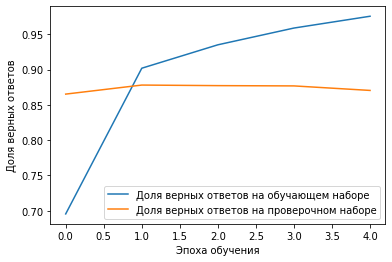

In [ ]:
plt.plot(history.history['accuracy'], 
         label='Доля верных ответов на обучающем наборе')
plt.plot(history.history['val_accuracy'], 
         label='Доля верных ответов на проверочном наборе')
plt.xlabel('Эпоха обучения')
plt.ylabel('Доля верных ответов')
plt.legend()
plt.show()

<a id="ai-026-section-06"></a>
## 06 · Отложенная оценка

Используйте тест после выбора настроек, отдельно от проверочной кривой.

_Далее — исходные ячейки учебного материала._

## Проверяем работу сети на тестовом наборе данных

In [ ]:
scores = model.evaluate(x_test, y_test, verbose=1)

782/782 [==============================] - 2s 3ms/step - loss: 0.5216 - accuracy: 0.8533


<a id="ai-026-practice"></a>
## Проверьте понимание

1. Как меняется длина после kernel_size=5 и pooling?
2. Какая часть длинного отзыва остаётся при исходном pad_sequences?
3. Почему test_data не участвует в model.fit?

### Один самостоятельный эксперимент

В копии сравните ядра размера 3 и 5 при одинаковом разбиении и пяти эпохах.

**Критерий успеха:** Записаны формы, число параметров и проверочная метрика; тест не используется для подбора.

<a id="ai-026-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/NLP/NLP_%D0%90%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D0%B8_%D0%A0%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D1%87%D0%B5%D1%80%D0%B5%D0%B7_Conv1d_%28accuracy_0_8533%29.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Датасет требует сети при первом получении; обучение здесь не выполнялось.
- %tensorflow_version и input_length зависят от версии среды; исходный код архивный.
- Случайность обучения не зафиксирована, поэтому сохранённые метрики не являются воспроизводимым новым замером.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.